In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

-------------------------------------------------------------------------------------------------------------------------------------------------------
Initial data analysis
-------------------------------------------------------------------------------------------------------------------------------------------------------

In [2]:
#Load dataset
df=pd.read_csv("creditcard.csv")

#Part 1: Exploratory Data Analysis (EDA) & Data Quality Checks
---

**Project Overview:**
This notebook focuses on the foundational Exploratory Data Analysis (EDA) and data pre-processing for a credit card fraud detection system. The dataset (sourced from Kaggle) contains credit card transactions made by European cardholders. Due to confidentiality constraints, the majority of the features (`V1` through `V28`) are principal components obtained via PCA transformation. The only native, untransformed features are `Time` and `Amount`.

**Objectives of this phase:**
1. **Data Quality Assessment:** Identify and handle missing values, duplicates, and structural anomalies.
2. **Statistical Profiling:** Analyze the distributions of the raw `Time` and `Amount` variables.
3. **Class Imbalance Analysis:** Evaluate the distribution of the target variable (`Class`) to inform downstream resampling strategies.
4. **Feature Engineering:** Apply mathematical transformations (log-scaling, trigonometric time encoding) to optimize the data space for machine learning algorithms.

In [3]:
print(df.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

### Dataset Architecture
The dataset has been successfully loaded into memory. It consists of 31 columns:
* **`V1` - `V28`**: Anonymized continuous numerical features resulting from a PCA transformation.
* **`Time`**: Seconds elapsed between each transaction and the first transaction in the dataset.
* **`Amount`**: The monetary value of the transaction.
* **`Class`**: The target variable representing the transaction validity (`0` = Legitimate, `1` = Fraudulent).

Before diving into feature distributions, we must validate the structural integrity of the dataframe by checking for missing values and duplicated records.

In [4]:
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("Dataset has no missing values.")
else:
    print("Missing values found.")
    display(missing_values[missing_values]>0)

Dataset has no missing values.


The dataset is perfectly complete with zero missing values. We can safely proceed to analyze the occurrence of duplicated records.

In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1081


### Handling Duplicated Records
The initial scan reveals 1,081 duplicated rows. In the context of this highly specific financial dataset, these duplicates will be dropped for the following strategic reasons:

1. The dataset contains 28 continuous PCA-transformed features (with high-precision decimals), alongside exact timestamps and transaction amounts. The probability of two distinct transactions sharing identical values across all 30 continuous variables is virtually zero. These are highly likely to be artifacts of system logging errors or data pipeline duplication.
2. If identical rows are randomly split between the training and testing sets, it would compromise the integrity of our cross-validation, artificially inflating model evaluation metrics.
3. Leaving duplicated fraudulent or legitimate transactions intact could shift the model's weights toward specific, repeated patterns, leading to overfitting and reduced generalizability.

In [6]:
df.drop_duplicates(inplace=True)
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


### Feature Profiling: Native Variables
Since features `V1` through `V28` are PCA-derived, their raw values lack direct business interpretability. Therefore, our univariate analysis will focus strictly on the unmodified, native features: `Amount` and `Time`. We will analyze their statistical properties to determine the required scaling and mathematical transformation strategies.

In [7]:
display(df[['Time', 'Amount']].describe())

,Time,Amount
count,283726.000000,283726.000000
mean,94811.077600,88.472687
std,47481.047891,250.399437
min,0.000000,0.000000
25%,54204.750000,5.600000
50%,84692.500000,22.000000
75%,139298.000000,77.510000
max,172792.000000,25691.160000


**Conclusions:**
1. **Severe Right-Skewness in `Amount`:** The mean transaction value is relatively low (~88 USD), with 75% of all transactions falling below 77 USD. However, the maximum recorded value exceeds 25,000 USD. This indicates a heavily right-skewed distribution with significant outliers.
2. **Preprocessing Strategy:** To optimize the dataset for machine learning models (especially those sensitive to variance), the `Amount` feature will require a logarithmic transformation (`np.log1p`) to compress the extreme tail, followed by a `RobustScaler` in the modeling pipeline to mitigate the influence of remaining outliers.

### Target Variable Distribution & Class Imbalance
Before constructing predictive models, we must evaluate the distribution of our target variable (`Class`) to establish an appropriate evaluation framework.

In [8]:
print("Class distribution:\n", df['Class'].value_counts(normalize=True))
print(40*"-")

Class distribution:
 Class
0    0.998333
1    0.001667
Name: proportion, dtype: float64
----------------------------------------


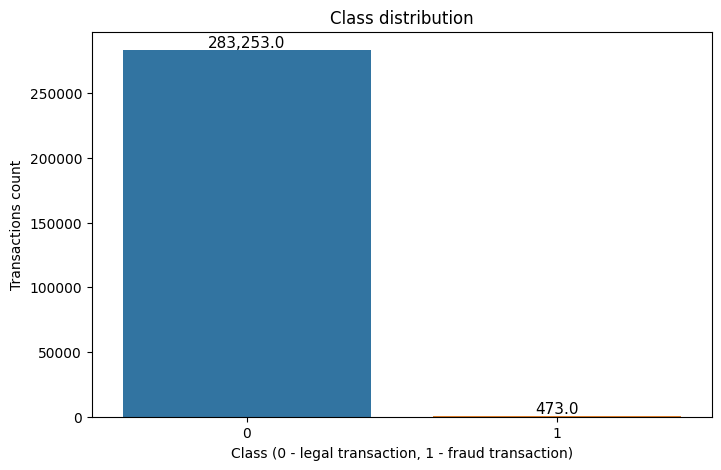

In [9]:
plt.figure(figsize=(8,5))
ax = sns.countplot(data=df, x='Class', hue ='Class', legend=False)
plt.title('Class distribution')
plt.xlabel('Class (0 - legal transaction, 1 - fraud transaction)')
plt.ylabel('Transactions count')

for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=11, color='black', xytext=(0,5),
                textcoords='offset points')

plt.show()

**Class Imbalance Impact & Strategy:**
The dataset exhibits extreme class imbalance, with fraudulent transactions accounting for a mere **0.17%** of the data. 

* **Metric Selection:** In this scenario, standard *Accuracy* is a misleading metric (a dummy model predicting all transactions as legal would achieve 99.8% accuracy). Model evaluation will instead strictly rely on **Precision-Recall AUC (AUCPR)**, **F1-Score**, and **Confusion Matrices** to focus on the minority class.
* **Resampling Strategy:** To prevent the models from heavily biasing toward the majority class during training, a hybrid resampling technique—**SMOTEENN** (Synthetic Minority Over-sampling Technique combined with Edited Nearest Neighbours)—will be implemented later in the pipeline to synthesize minority samples and clean noisy decision boundaries.

### Transaction Value Profiling by Class
To uncover behavioral differences, let's compare the statistical properties of transaction amounts between legitimate customers and fraudsters.

In [10]:
print("Regular transactions - Amount stats:\n", df[df['Class'] == 0].Amount.describe())
print(40*"-")
print("Fraudulent transactions = Amount stats:\n", df[df['Class'] == 1].Amount.describe())
print(40*"-")

Regular transactions - Amount stats:
 count    283253.000000
mean         88.413575
std         250.379023
min           0.000000
25%           5.670000
50%          22.000000
75%          77.460000
max       25691.160000
Name: Amount, dtype: float64
----------------------------------------
Fraudulent transactions = Amount stats:
 count     473.000000
mean      123.871860
std       260.211041
min         0.000000
25%         1.000000
50%         9.820000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64
----------------------------------------


**Key Behavioral Observation:**
While the average fraudulent transaction (123 USD) is higher than the average legitimate one (88 USD), the absolute maximums tell a different story. The largest fraudulent transaction is capped at 2,125 USD, whereas legitimate transactions reach over 25,000 USD. This confirms that **extreme monetary outliers belong exclusively to legitimate behavior**, an insight that validates our earlier decision to carefully scale the `Amount` feature rather than blindly drop outliers.

### Correlation Analysis
Because features `V1` through `V28` were generated via Principal Component Analysis (PCA), they are mathematically orthogonal, meaning they exhibit zero multicollinearity by design. Therefore, our heatmap analysis will focus exclusively on identifying which features show the strongest linear correlation with the target `Class`.

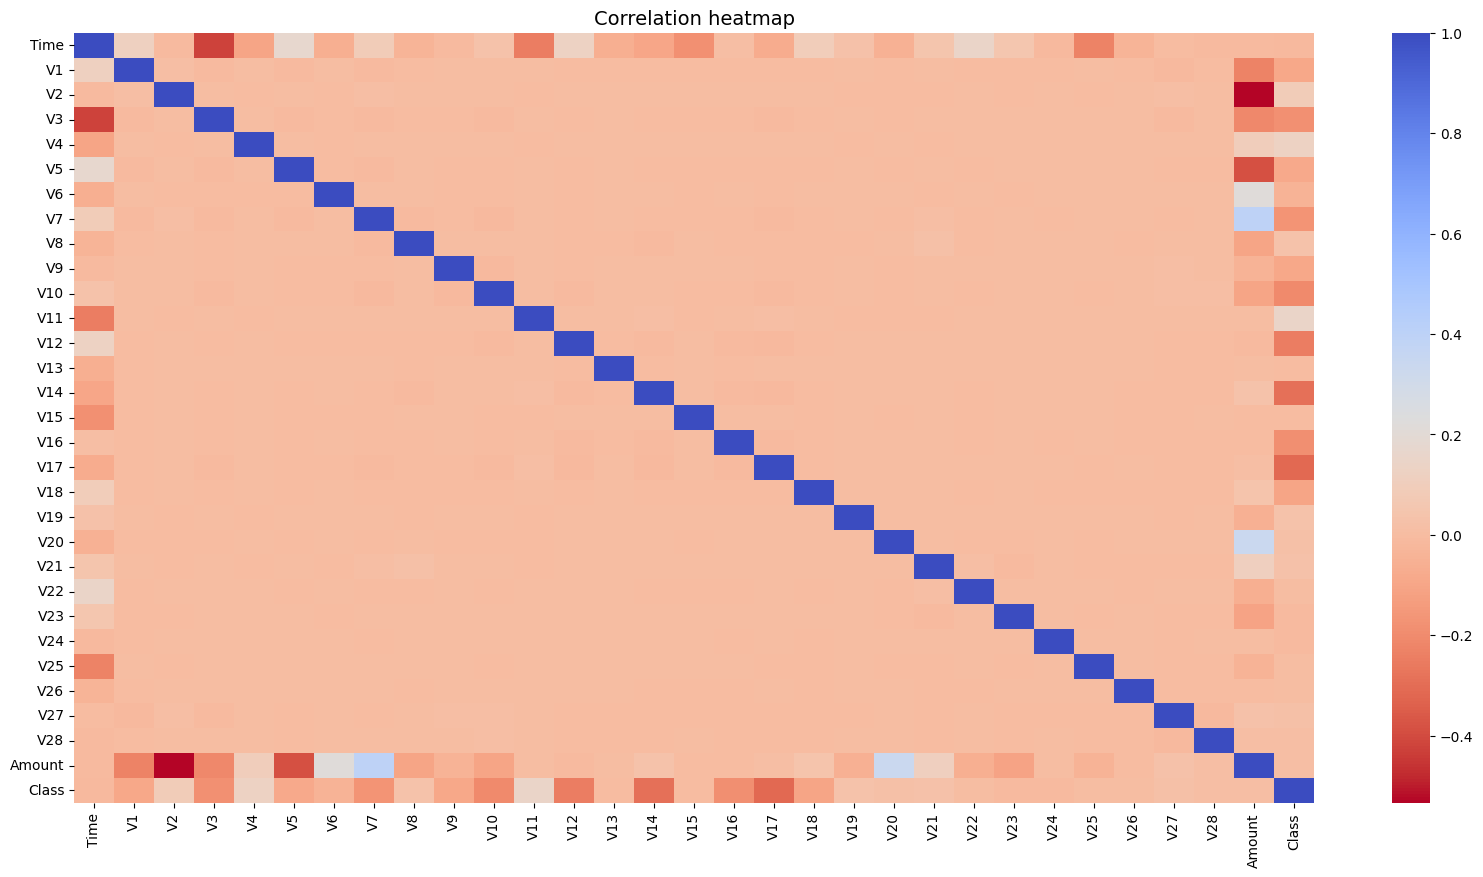

In [11]:
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(), cmap='coolwarm_r', annot_kws={'size':20})
plt.title('Correlation heatmap', fontsize=14)
plt.show()

In [24]:
correlations = df.corr()['Class'].sort_values(ascending=False)
print("Biggest positive correlations with Class:\n", correlations.head())
print(40*"-")
print("Biggest negative correlations with Class:\n", correlations.tail())
print(40*"-")

Biggest positive correlations with Class:
 Class    1.000000
V11      0.149067
V4       0.129326
V2       0.084624
V19      0.033631
Name: Class, dtype: float64
----------------------------------------
Biggest negative correlations with Class:
 V16   -0.187186
V10   -0.206971
V12   -0.250711
V14   -0.293375
V17   -0.313498
Name: Class, dtype: float64
----------------------------------------


**Correlation Findings:**
* **Positive Drivers:** Features `V11`, `V4`, and `V2` exhibit the highest positive correlation with fraud. Elevated values in these components signal a higher probability of malicious activity.
* **Negative Drivers:** Conversely, `V17`, `V14`, and `V12` demonstrate strong negative correlations. Lower values in these dimensions act as powerful indicators of fraudulent transactions.
* **Modeling Note:** These top six features will likely dominate the decision-making process of our tree-based algorithms.

As all of the features are numerical values, models will be able to learn and make predictions without any pre-processing. We will use this raw data to train benchmark models. (Please see notebooks models for benchmarking models training and validation)

Benchmark data which is a result of initial processing in above section can be found in 'Data' folder.

# Part 2: Advanced Feature Engineering
---
While raw data (including baseline `Time` and `Amount`) was utilized to establish initial model benchmarks, optimizing the data space is a crucial prerequisite for our upcoming resampling and scaling strategies. 

**Why is this optimization strictly necessary?**
To address the extreme class imbalance, we plan to use **SMOTEENN**, which relies on the K-Nearest Neighbors (KNN) algorithm under the hood. Because KNN calculates mathematical distances (e.g., Euclidean) between data points, it is highly sensitive to feature scales. If we leave `Amount` in its raw, expansive scale (up to 25,000 USD) alongside standard PCA features (mostly ranging between -3 and +3), the distance calculations would be entirely dominated by the monetary value, leading to poorly synthesized minority samples.

**Transformation Roadmap:**
1. **Variance Compression:** The `Amount` feature will undergo a logarithmic transformation (`np.log1p`) to normalize its heavily right-skewed distribution. This compresses the extreme tail and prepares the feature perfectly for a `RobustScaler`, which will standardize the entire data space before resampling.
2. **Temporal Encoding:** The raw `Time` feature (seconds elapsed) will be converted into a 24-hour format. To allow algorithms to understand the cyclical nature of time (e.g., that 23:00 is mathematically close to 01:00), we will apply **cyclical encoding using sine and cosine transformations**.

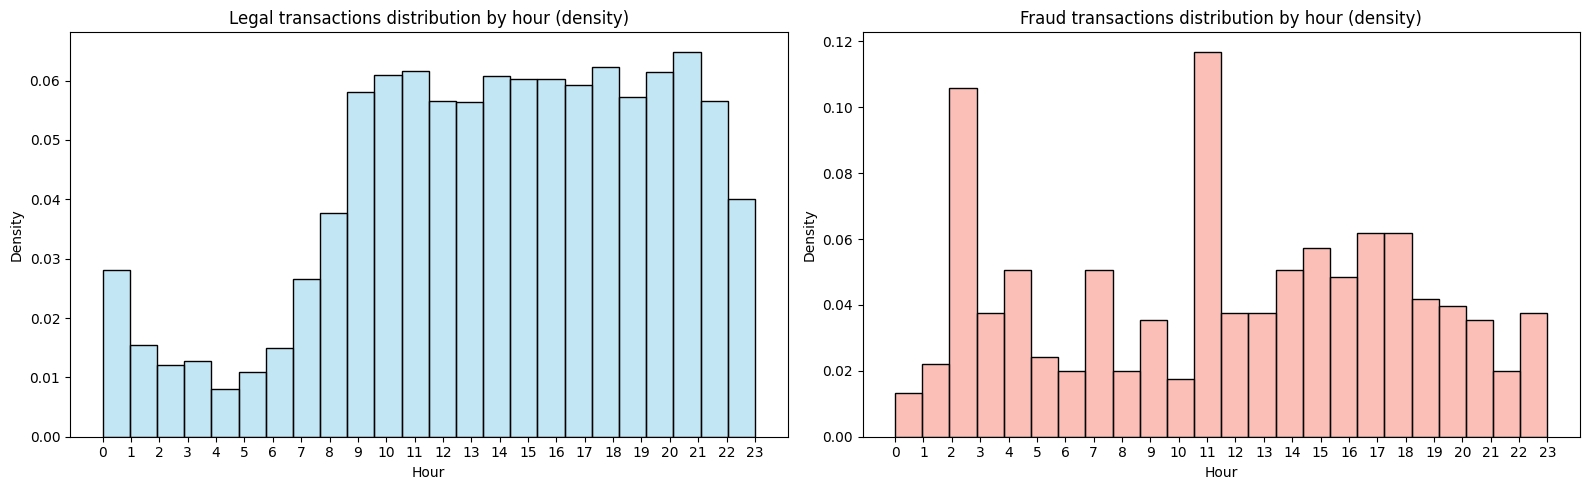

In [10]:
df_clean = df.copy()
df_clean['Hour'] = (df_clean['Time'] // 3600) % 24
#visualizng data
fig, ax = plt.subplots(1, 2, figsize = (16,5))
sns.histplot(data=df_clean[df_clean['Class']==0], x='Hour', color = 'skyblue', bins = 24, stat='density', alpha= 0.5, ax=ax[0])
ax[0].set_title('Legal transactions distribution by hour (density)')
ax[0].set_xticks(range(0,24))
ax[0].set_xlabel('Hour')
ax[0].set_ylabel('Density')

sns.histplot(data=df_clean[df_clean['Class']==1], x='Hour', color = 'salmon', bins = 24, stat='density', alpha= 0.5, ax=ax[1])
ax[1].set_title('Fraud transactions distribution by hour (density)')
ax[1].set_xticks(range(0,24))
ax[1].set_xlabel('Hour')
ax[1].set_ylabel('Density')

plt.tight_layout()
plt.show()

Skewness before transformation: 16.98
Skewness after transformation: 0.16


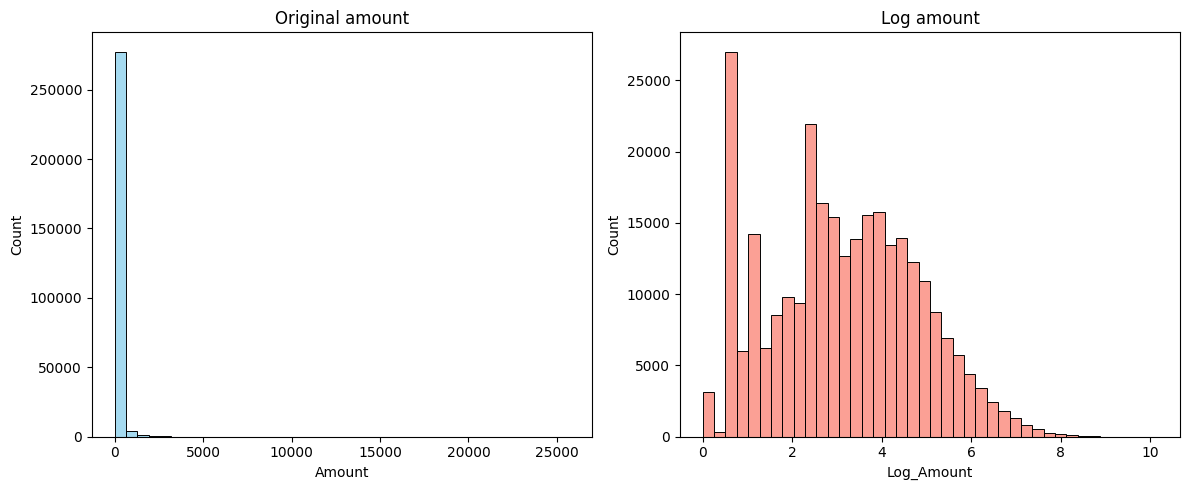

In [11]:
skew_before = df_clean['Amount'].skew()
df_clean['Log_Amount'] = np.log1p(df_clean['Amount'])
skew_after = df_clean['Log_Amount'].skew()
print(f"Skewness before transformation: {skew_before:.2f}")
print(f"Skewness after transformation: {skew_after:.2f}")

#visualizng data
fig, ax = plt.subplots(1, 2, figsize = (12,5))
sns.histplot(df_clean['Amount'], bins=40, ax=ax[0], color='skyblue').set_title('Original amount')
sns.histplot(df_clean['Log_Amount'], bins=40, ax=ax[1], color='salmon').set_title('Log amount')
plt.tight_layout()
plt.show()

In [12]:
df_clean.drop(['Amount', 'Time'], axis=1, inplace=True)

In [13]:
df_clean['Hour_sin'] = np.sin(2 * np.pi * df_clean['Hour'] /24)
df_clean['Hour_cos'] = np.cos(2 * np.pi * df_clean['Hour'] / 24)
df_clean.drop(['Hour'], axis=1, inplace=True)

**Feature Engineering Complete:** 
The dataset successfully integrates `Log_Amount` and trigonometric time representations (`Hour_sin`, `Hour_cos`). The transformed dataset will be exported for the final model training and validation pipeline.